# TP1 - CLIP

## Question 2

*Quels sont les différents modèles de CLIP disponibles ? Proposez une évaluation quantitative et une confrontation de ces différents modèles*

In [1]:
import clip

models = clip.available_models()

print("Available CLIP models :")
for model in models:
    print(model)

Available CLIP models :
RN50
RN101
RN50x4
RN50x16
RN50x64
ViT-B/32
ViT-B/16
ViT-L/14
ViT-L/14@336px


In [ ]:
import clip
import torch
import numpy as np

from torchvision.datasets import CIFAR100
from torch.utils.data import DataLoader
from tqdm import tqdm

device = "cuda" if torch.cuda.is_available() else "cpu"

# Dataset
dataset = CIFAR100(
    root="./data",
    train=False,
)
print(len(dataset))


results = []

for model_name in clip.available_models():

    print(f"\nEvaluating {model_name}")

    model, preprocess = clip.load(
        model_name,
        device=device
    )

    model.eval()

    # Dataset with model-specific preprocessing
    dataset.transform = preprocess

    loader = DataLoader(
        dataset,
        batch_size=128,
        shuffle=False,
        num_workers=4
    )

    # Text embeddings
    classes = dataset.classes

    texts = torch.cat([
        clip.tokenize(f"a photo of a {c}")
        for c in classes
    ]).to(device)

    with torch.no_grad():
        text_features = model.encode_text(texts)
        text_features /= text_features.norm(dim=-1, keepdim=True)

    correct = 0
    total = 0
    top1_correct = 0
    top5_correct = 0

    with torch.no_grad():
        

        for images, labels in tqdm(loader):
            

            images = images.to(device)
            labels = labels.to(device)

            image_features = model.encode_image(images)
            image_features /= image_features.norm(dim=-1, keepdim=True)

            similarity = image_features @ text_features.T

            top5_predictions = similarity.topk(5, dim=1).indices

            # Top-1 accuracy
            top1_correct += (
                top5_predictions[:, 0] == labels
            ).sum().item()

            # Top-5 accuracy
            top5_correct += (
                top5_predictions == labels.unsqueeze(1)
            ).any(dim=1).sum().item()

            total += labels.size(0)

    top1_accuracy = 100 * top1_correct / total
    top5_accuracy = 100 * top5_correct / total
    
    results.append({
        "model": model_name,
        "top1_accuracy": top1_accuracy,
        "top5_accuracy": top5_accuracy
    })

    print(f"Top-1 Accuracy: {top1_accuracy:.2f}%")
    print(f"Top-5 Accuracy: {top5_accuracy:.2f}%")

    del model
    if device == "cuda":
        torch.cuda.empty_cache()



c:\Users\coude\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torchvision\datasets\cifar.py:83: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  entry = pickle.load(f, encoding="latin1")


10000

Evaluating RN50


c:\Users\coude\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\jit\_serialization.py:170: FutureWarning: `torch.jit.load` is not supported in Python 3.14+ and may break. Please switch to `torch.export`.
  warnings.warn(
100%|██████████| 79/79 [00:33<00:00,  2.38it/s]


Top-1 Accuracy: 39.04%
Top-5 Accuracy: 70.91%

Evaluating RN101


100%|██████████| 79/79 [00:43<00:00,  1.83it/s]


Top-1 Accuracy: 41.41%
Top-5 Accuracy: 72.65%

Evaluating RN50x4


... (10 outputs left out)

100%|████████████████████████████████████████| 890M/890M [00:08<00:00, 114MiB/s]
100%|██████████| 79/79 [02:05<00:00,  1.58s/it]


Top-1 Accuracy: 73.28%
Top-5 Accuracy: 91.94%

Evaluating ViT-L/14@336px


100%|███████████████████████████████████████| 891M/891M [00:17<00:00, 54.4MiB/s]
100%|██████████| 79/79 [04:21<00:00,  3.32s/it]

Top-1 Accuracy: 72.00%
Top-5 Accuracy: 91.80%


In [12]:
# Results
print("===== Top 1 accuracy =====")
sorted_top1 = sorted(results, key=lambda x: x["top1_accuracy"], reverse=True)
for model_result in sorted_top1:
    print(f"{model_result["model"]:20s} {model_result["top1_accuracy"]:.2f}%")

print("\n===== Top 5 accuracy =====")
sorted_top5 = sorted(results, key=lambda x: x["top5_accuracy"], reverse=True)
for model_result in sorted_top5:
    print(f"{model_result["model"]:20s} {model_result["top5_accuracy"]:.2f}%")

===== Top 1 accuracy =====
ViT-L/14             73.28%
ViT-L/14@336px       72.00%
ViT-B/16             64.70%
ViT-B/32             61.75%
RN50x64              52.10%
RN50x16              46.13%
RN101                41.41%
RN50                 39.04%
RN50x4               36.91%

===== Top 5 accuracy =====
ViT-L/14             91.94%
ViT-L/14@336px       91.80%
ViT-B/16             86.95%
ViT-B/32             86.74%
RN50x64              77.92%
RN50x16              72.95%
RN101                72.65%
RN50                 70.91%
RN50x4               65.67%


## Question 3

*Montrer les résultats de CLIP dans le domaine médical sur d’autres exemples du jeu de données*

In [ ]:
import os
import random
import pandas as pd

path_images = os.path.join("data", "pretrain_data", "roco", "test", "radiology", "images")
path_captions = os.path.join("data", "pretrain_data", "roco", "test", "radiology", "captions.txt")

def get_random_imgs_from_radiology_test_dataset(n: int):
    df = pd.read_csv(path_captions, sep=r"\t+", header=None, names=["img_name", "description"])
    img_names = df["img_name"].tolist()
    descriptions = df["description"].tolist()

    random_indices = random.sample(range(len(img_names)), n)
    selected_img_paths = [path_images + "/" + img_names[indice] + ".jpg" for indice in random_indices]
    selected_descriptions = [descriptions[indice] for indice in random_indices]
    
    return selected_img_paths, selected_descriptions

In [91]:
import matplotlib.pyplot as plt
from PIL import Image

def compute_and_display_similarity(model, preprocess, img_paths: list[str], texts: list[str]):
    assert len(img_paths) == len(texts)

    original_images = []
    images = []
    for filename in list(img_paths):
        image = Image.open(filename)
        original_images.append(image)
        images.append(preprocess(image))

    image_input = torch.tensor(np.stack(images)).cuda()
    text_tokens = clip.tokenize(["This is " + desc for desc in texts]).cuda()
    with torch.no_grad():
        image_features = model.encode_image(image_input).float()
        text_features = model.encode_text(text_tokens).float()
    image_features /= image_features.norm(dim=-1, keepdim=True)
    text_features /= text_features.norm(dim=-1, keepdim=True)
    similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

    count = len(med_descriptions)

    plt.figure(figsize=(20, 14))
    plt.imshow(similarity, vmin=0.1, vmax=0.3)
    plt.yticks(range(count), texts, fontsize=18)
    plt.xticks([])
    for i, image in enumerate(original_images):
        plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
    for x in range(similarity.shape[1]):
        for y in range(similarity.shape[0]):
            plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)

    for side in ["left", "top", "right", "bottom"]:
        plt.gca().spines[side].set_visible(False)

    plt.xlim([-0.5, count - 0.5])
    plt.ylim([count + 0.5, -2])

    plt.title("Cosine similarity between text and image features(medical)", size=20)

C:\Users\coude\AppData\Local\Temp\ipykernel_20752\2412587164.py:10: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df = pd.read_csv(path_captions, sep=r"\t+", header=None, names=["img_name", "description"])
c:\Users\coude\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\jit\_serialization.py:170: FutureWarning: `torch.jit.load` is not supported in Python 3.14+ and may break. Please switch to `torch.export`.
  warnings.warn(


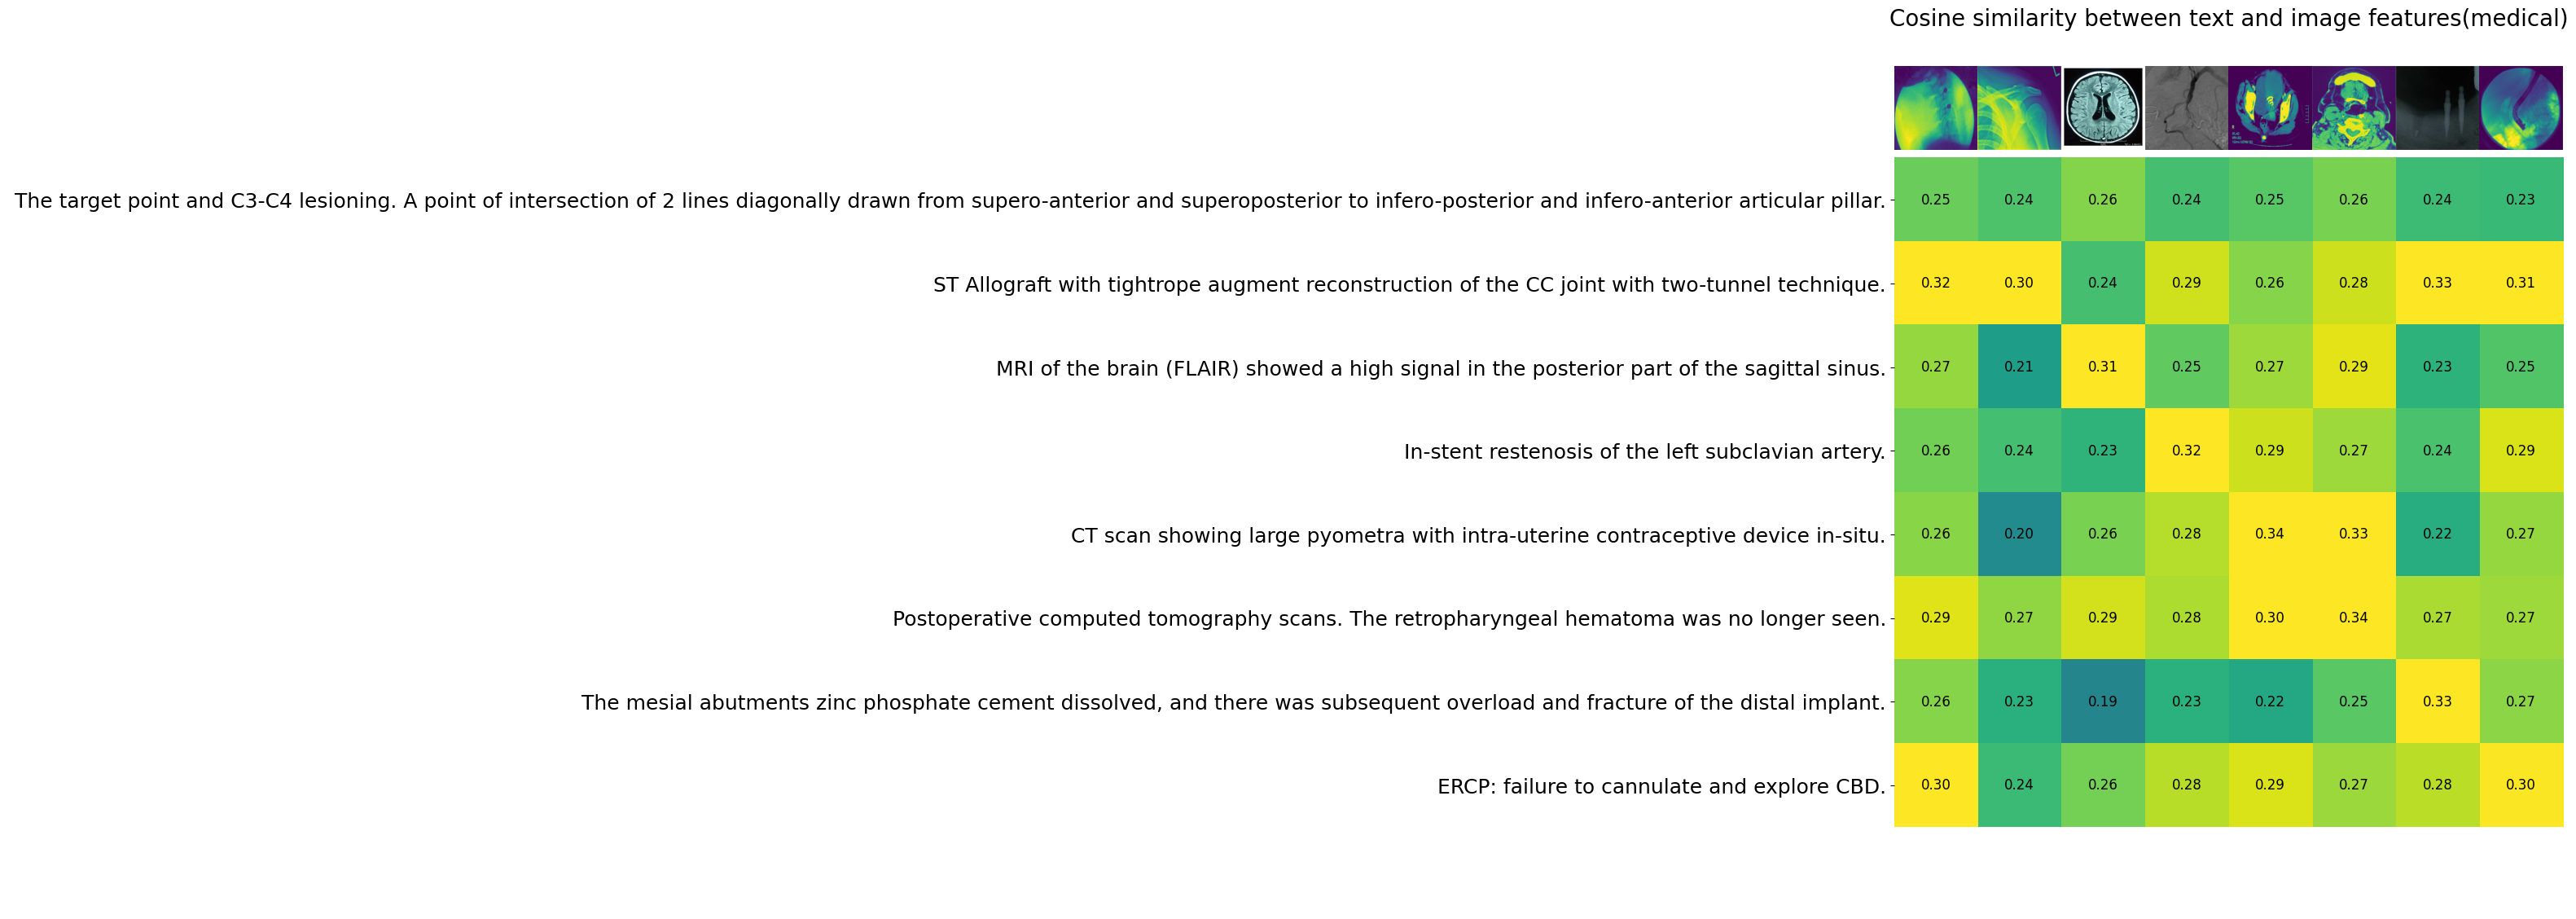

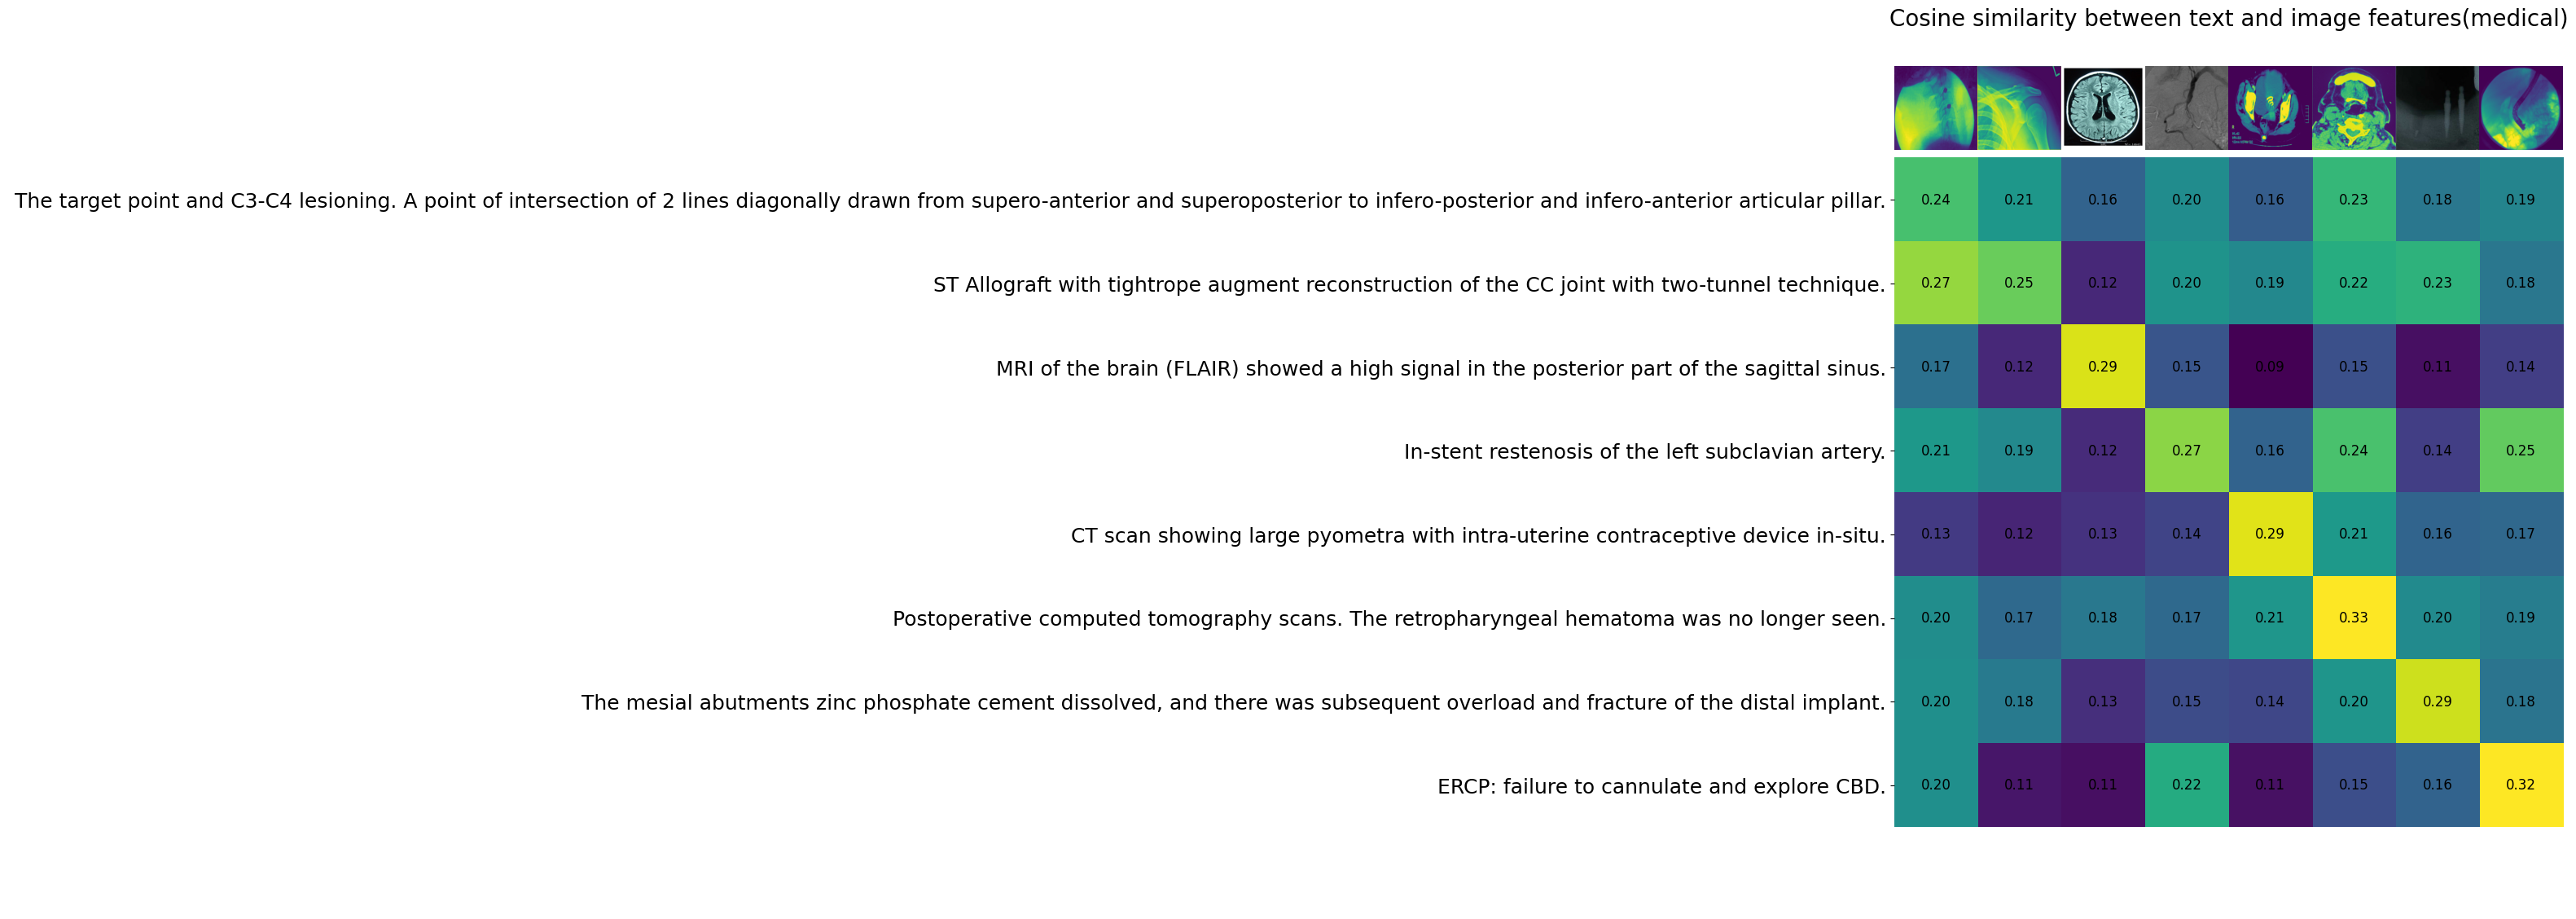

In [98]:
img_paths, texts = get_random_imgs_from_radiology_test_dataset(8)

# Compute similarity on base model
model, preprocess = clip.load("ViT-B/16", device=device)
compute_and_display_similarity(model, preprocess, img_paths, texts)

# After training on medical images
model.load_state_dict(torch.load('data/ViT-B-16_best_checkpoint_2.tar'))
compute_and_display_similarity(model, preprocess, img_paths, texts)

## Question 4

*Calculer les performances de CLIP sur une tâche de classification d’images naturelles, sur un autre jeu de données que CIFAR100*

In [80]:
from torchvision.datasets import Caltech101

dataset = Caltech101(
    root = "./data",
    #download = True
)

In [81]:
def compute_and_display_similarity_from_direct_images(model, preprocess, imgs, texts: list[str]):
    assert len(imgs) == len(texts)
    
    images = [preprocess(img) for img in imgs]

    image_input = torch.tensor(np.stack(images)).cuda()
    text_tokens = clip.tokenize(["This is " + desc for desc in texts]).cuda()
    with torch.no_grad():
        image_features = model.encode_image(image_input).float()
        text_features = model.encode_text(text_tokens).float()
    image_features /= image_features.norm(dim=-1, keepdim=True)
    text_features /= text_features.norm(dim=-1, keepdim=True)
    similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

    count = len(med_descriptions)

    plt.figure(figsize=(20, 14))
    plt.imshow(similarity, vmin=0.1, vmax=0.3)
    plt.yticks(range(count), texts, fontsize=18)
    plt.xticks([])
    for i, image in enumerate(imgs):
        plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
    for x in range(similarity.shape[1]):
        for y in range(similarity.shape[0]):
            plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)

    for side in ["left", "top", "right", "bottom"]:
        plt.gca().spines[side].set_visible(False)

    plt.xlim([-0.5, count - 0.5])
    plt.ylim([count + 0.5, -2])

    plt.title("Cosine similarity between text and image features(medical)", size=20)

In [88]:
# 8 random images
random_indices = random.sample(range(len(dataset)), 8)

images = []
class_names = []
for indice in random_indices:
    image, label = dataset[indice]
    class_name = dataset.categories[label]
    
    images.append(image)
    class_names.append(class_name)

c:\Users\coude\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\jit\_serialization.py:170: FutureWarning: `torch.jit.load` is not supported in Python 3.14+ and may break. Please switch to `torch.export`.
  warnings.warn(


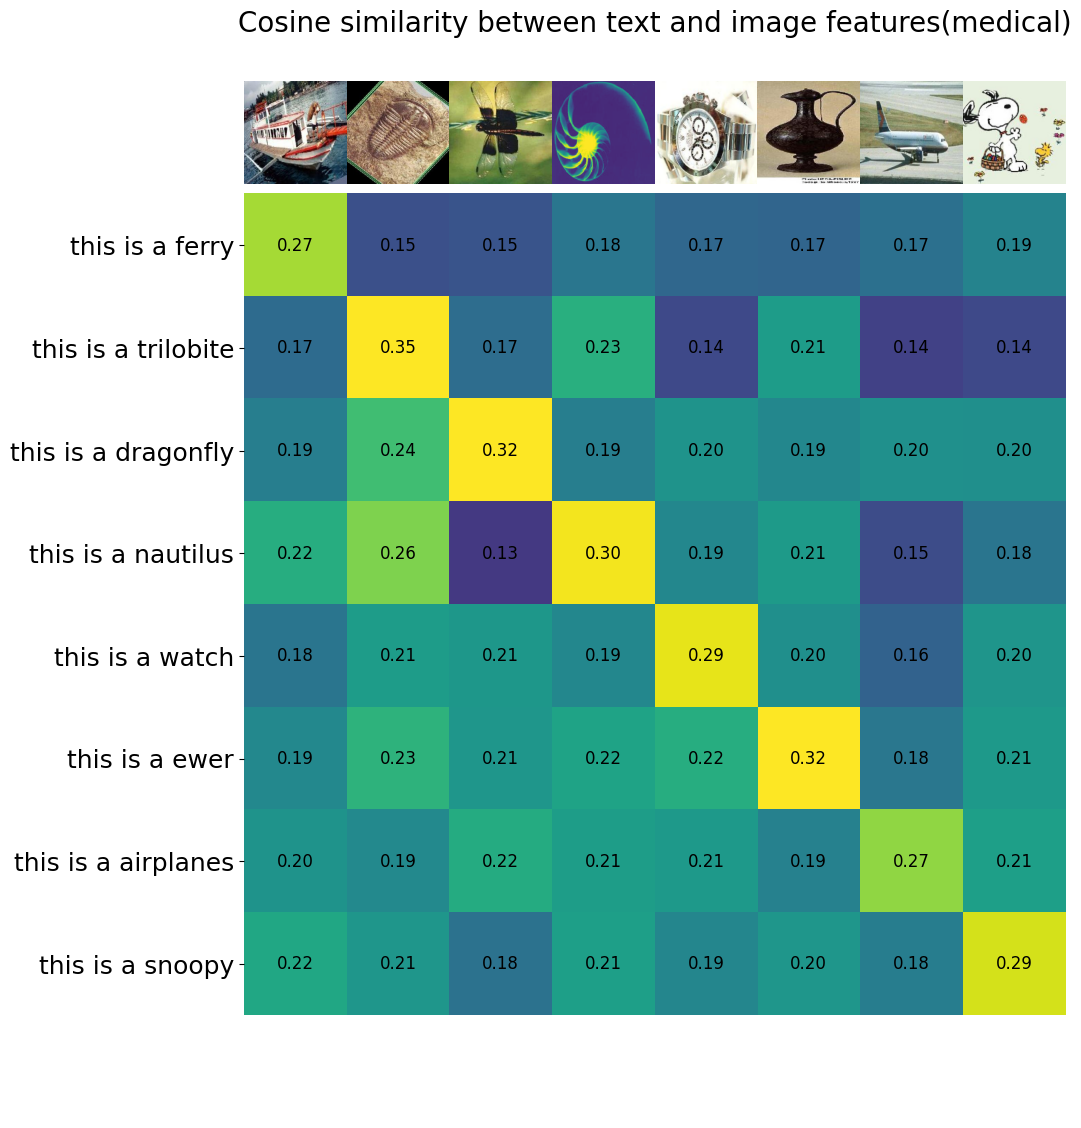

In [89]:
model, preprocess = clip.load("ViT-B/16")

texts = [f"this is a {class_name}" for class_name in class_names]
compute_and_display_similarity_from_direct_images(model, preprocess, images, texts)


In [77]:
device = "cuda" if torch.cuda.is_available() else "cpu"

# Dataset
dataset = Caltech101(
    root="./data",
)
print(f"{len(dataset)} in the Caeltech101 dataset")

model, preprocess = clip.load("ViT-B/16")
model.eval()
dataset.transform = preprocess

loader = DataLoader(
    dataset,
    batch_size=128,
    shuffle=False,
    num_workers=4
)

classes = dataset.categories
texts = torch.cat([
    clip.tokenize(f"a photo of a {c}")
    for c in classes
]).to(device)

with torch.no_grad():
    text_features = model.encode_text(texts)
    text_features /= text_features.norm(dim=-1, keepdim=True)

correct = 0
total = 0
top1_correct = 0
top5_correct = 0

with torch.no_grad():
    for images, labels in tqdm(loader):
        images = images.to(device)
        labels = labels.to(device)

        image_features = model.encode_image(images)
        image_features /= image_features.norm(dim=-1, keepdim=True)

        similarity = image_features @ text_features.T

        top5_predictions = similarity.topk(5, dim=1).indices

        # Top-1 accuracy
        top1_correct += (
            top5_predictions[:, 0] == labels
        ).sum().item()

        # Top-5 accuracy
        top5_correct += (
            top5_predictions == labels.unsqueeze(1)
        ).any(dim=1).sum().item()

        total += labels.size(0)

top1_accuracy = 100 * top1_correct / total
top5_accuracy = 100 * top5_correct / total

print(f"Top-1 Accuracy: {top1_accuracy:.2f}%")
print(f"Top-5 Accuracy: {top5_accuracy:.2f}%")

del model
if device == "cuda":
    torch.cuda.empty_cache()


8677 in the Caeltech101 dataset


c:\Users\coude\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\torch\jit\_serialization.py:170: FutureWarning: `torch.jit.load` is not supported in Python 3.14+ and may break. Please switch to `torch.export`.
  warnings.warn(
100%|██████████| 68/68 [00:38<00:00,  1.76it/s]

Top-1 Accuracy: 85.57%
Top-5 Accuracy: 98.26%
